# Applied Modelling and Visualisation
---
**Notebook structure**

- **Part A:** Dataset rationale and research questions 
- **Part B:** Exploratory data analysis (EDA)
  - **Task 1:** Data collection and preprocessing 
  - **Task 2:** Exploratory data analysis, expanded 
  - **Task 3:** Modelling and analysis 
  - **Task 4:** Visualisation of results, including one interactive visualisation 
- **Conclusion, limitations and references** 

---

## Dataset Rationale and Research Questions

### Dataset and source

The Consumer Complaint Database is open government data published by the US **Consumer
Financial Protection Bureau (CFPB)** see
[consumerfinance.gov](https://www.consumerfinance.gov/data-research/consumer-complaints/) (Consumer Financial Protection Bureau, 2026).
It records consumer complaints about financial products and services, which the CFPB forwards
to firms for response. It holds ~13.8 million complaints dating back to 2011, updated daily,
accessible via a public API. Each record is date-stamped and includes the product and
sub-product, the issue, the company, the channel it was submitted via, the company response,
and whether the response was timely.
* Note: the formative pulls 2023 – 2025 only (~375,000 records).
* I have extended uponn this for the summative, including the COVID period: 2020 to 2025 (~420,000 records).

### Justification and relevance

Complaint handling sits at the centre of retail-banking operations and is increasingly mediated
by automated systems (chatbots and virtual agents) — directly relevant to my professional
context. The dataset also supports a responsible-AI lens: the timely-response, tags, and
ZIP-code fields let us examine the fairness and consistency of complaint outcomes across
products and over time, which matters when automation enters complaint triage. Although
US-sourced, the dynamics generalise to UK retail banking, which runs an analogous complaints
regime under the Financial Conduct Authority (Financial Conduct Authority (FCA), 2016) . Each record is time-stamped and therefore a suitable time series
for trend, seasonality and forecasting, while the categorical fields support statistical
modelling and correlation analysis.

### Research questions (RQ)

1. **Volume forecasting (capacity planning):** Can monthly complaint volume be forecast
   accurately enough (ARIMA/SARIMA) to support complaint-team staffing and reduce monetary payouts?
2. **Shifting mix (product oversight):** Which products and issues dominate complaints, and is
   that mix shifting in ways that should redirect root-cause remediation and product oversight?
3. **Outcome fairness (conduct / operational risk):** Which factors are associated with a firm
   failing to respond in a timely way, and do late responses cluster by product or channel in a
   way that signals operational or conduct-risk exposure?
4. **Channel & self-service (digital strategy):** Has the submission-channel mix shifted toward
   digital self-service, and does that shift coincide with worse timeliness or dispute
   outcomes; flagging a self-service quality problem?

## Exploratory Data Analysis (EDA)

This is an initial exploration to confirm the dataset is fit for purpose and to sharpen the
research questions. The heavier cleaning, transformation and modelling
will be done in the summative.

### Task 0: Project set up

* It is recommended to use a virtual environment (venv) to keep packages independent from the base directory, and ensure reproducibility (Python Software Foundation, 2026) 
* I have used Astral's `uv` for package management and venv maintenance for ease and efficiency (Astral, n.d.) available here: https://docs.astral.sh/uv/
* For completeness, I have attached the `pyproject.toml` file for setting up the same environment via the command `uv sync`
- However, users are able to install the same packages directly via their notebook using the following:
```python
   %pip install \
     "requests>=2.32.0" \
     "numpy>=2.0.0" \
     "pandas>=2.2.0" \
     "matplotlib>=3.9.0" \
     "scikit-learn>=1.7.2" \
     "statsmodels>=0.14.6" \
     "plotly>=7.0.0" \
     "scipy>=1.15.3" \
     "ipykernel>=7.3.0"
``` 


In [1]:
# Core libraries
import io
import time
import textwrap

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

RANDOM_STATE = 42  # reproducibility for any sampling / train-test splits

### Task 1: Data Collection and Preprocessing

Building on the formative import and the data-quality issues it surfaced (structural
missingness, severe class imbalance, unparsed dates), this task rebuilds the extract step to be usable, and then cleans and transforms the data ready for the Task 3 models.

Two structural findings drive the rest of this task, both only visible once the full window is
loaded rather than sampled: a level-shift in monthly volume around September 2023, and a
one-month volume spike in January 2025. Both are investigated below rather than assumed away.

#### 1. Importing the data

The CFPB exposes a public search API. We request a **bounded slice** using a date window and a
small set of retail-banking-relevant products so the pull stays manageable while still
reflecting live, government-published data. I have chosen to use credit cards, and checking / savings account for simplicity and applicability to the UK-context.

##### Important update for the summative:
> Two things changed on the CFPB side since the formative pull (both confirmed by testing the live API directly): 
> 1. the bulk CSV export (`format=csv`) now
> returns an HTTP 400 regardless of parameters, and 
> 2. CFPB renamed *Credit card* to *Credit card
> or prepaid card*. See error below:
```error
HTTPError: 400 Client Error: Bad Request for url: https://www.consumerfinance.gov/data-research/consumer-complaints/search/api/v1/?date_received_min=2023-01-01&date_received_max=2025-12-31&format=csv&no_aggs=true&product=Credit+card&product=Checking+or+savings+account
```
> The extract function below therefore uses the documented JSON search
> endpoint, paginated with the API's own `search_after` cursor, and updates the product filter —
> see Task 1 for detail. The JSON endpoint still returns the narrative text where consented,
> plus a ready-made `has_narrative` flag equivalent to the formative's hand-derived one.

##### Reproducibility: no file is shipped with this notebook. 
- The data is pulled live from the CFPB API. 
- If prefered, the full dataset can be downloaded once from the
[CFPB download page](https://www.consumerfinance.gov/data-research/consumer-complaints/#download-the-data) and read from disk instead.

In [ ]:
# --- Query parameters ---
API_URL   = "https://www.consumerfinance.gov/data-research/consumer-complaints/search/api/v1/"
DATE_MIN  = "2020-01-01"          # start of the window (includes COVID period)
DATE_MAX  = "2025-12-31"          # end of the window
PRODUCTS  = [                      # retail-banking-relevant products
    "Credit card or prepaid card",     # CFPB renamed this since the formative (was "Credit card")
    "Checking or savings account",
]
PAGE_SIZE = 10_000           # largest page size the live API accepts in practice
RATE_LIMIT_PAUSE = 1.5       # seconds between pages, to stay under the API's rate limit

# The JSON endpoint already returns snake_case field names matching the formative's previous schema,
# with two renames for consistency with Part B's naming: "timely" -> "timely_response" and
# "complaint_what_happened" -> "narrative".
COLUMN_MAP = {"timely": "timely_response", "complaint_what_happened": "narrative"}

In [ ]:
def fetch_cfpb_page(session, date_min, date_max, products, size, search_after=None,
                     url=API_URL, timeout=90):
    """Fetch one page (up to `size` rows) from the CFPB JSON search endpoint.

    `search_after` is the Elasticsearch cursor (bookmark) from the previous page's last hit Note: passing it
    lets us page past the 10,000-row ceiling on the `from` parameter.

    Args:
        session: An active ``requests.Session`` used to make the HTTP request.
            Reusing a session allows connection pooling across pages.
        date_min: Inclusive lower bound for ``date_received``, in the date
            format expected by the CFPB API.
        date_max: Inclusive upper bound for ``date_received``, in the date
            format expected by the CFPB API.
        products: Product names to include in the search. Each product is
            submitted as a separate ``product`` query parameter.
        size: Maximum number of records to request from the API.
        search_after: Cursor returned by the previous page's final hit.
            Pass ``None`` when requesting the first page.
        url: CFPB JSON search endpoint URL.
        timeout: Maximum number of seconds to wait for the HTTP response.

    Returns:
        The decoded JSON response from the CFPB API. The response is expected
        to contain complaint records under ``payload["hits"]["hits"]``.

    Raises:
        requests.HTTPError: If the API returns an unsuccessful HTTP status.
        requests.RequestException: If a network-level request error occurs.
        ValueError: If the response cannot be decoded as JSON.
    """
    params = [
        ("date_received_min", date_min),
        ("date_received_max", date_max),
        ("no_aggs", "true"),
        ("size", size),
        ("sort", "created_date_asc"),   # a stable sort order is required for cursor pagination
    ]
    params += [("product", p) for p in products]   # one entry per product
    if search_after is not None:
        params.append(("search_after", search_after))

    response = session.get(url, params=params, timeout=timeout)
    response.raise_for_status()
    return response.json()


def fetch_cfpb(date_min, date_max, products, page_size=PAGE_SIZE, max_pages=100):
    """Download a bounded slice of the CFPB complaint database as a DataFrame.

    View the API documentation here: https://cfpb.github.io/api/ccdb/api.html

    Modular by design: `fetch_cfpb_page` does one HTTP call, whereas this function owns the pagination,
    retry and rate-limit logic, and the final tidy-up (renaming, date parsing)..
    Retries on HTTP 429 using the server's own `Retry-After` header, and reports progress per page so a multi-minute pull is observable.

    The CFPB JSON endpoint already returns snake_case field names. The result
    is normalised to the project's established schema by renaming
    ``timely`` to ``timely_response`` and
    ``complaint_what_happened`` to ``narrative``.

    Args:
        date_min: Inclusive lower bound for ``date_received``, in the date
            format expected by the CFPB API.
        date_max: Inclusive upper bound for ``date_received``, in the date
            format expected by the CFPB API.
        products: Product names to include in the search.
        page_size: Number of records to request per API page.
        max_pages: Maximum number of pages to retrieve. This prevents an
            unexpectedly large download.

    Returns:
        A pandas DataFrame containing the matching CFPB complaints after
        pagination and cleanup.

    Raises:
        RuntimeError: If ``max_pages`` is exceeded or repeated HTTP 429
            responses continue after all retry attempts.
        requests.HTTPError: If the API returns an HTTP error other than 429.
        requests.RequestException: If a network-level request error occurs.
        KeyError: If the API response does not have the expected JSON fields.
        ValueError: If a response cannot be decoded as JSON or contains values
            that cannot be converted as expected.
    """
    session = requests.Session()
    records, search_after, total, page = [], None, None, 0

    while True:
        page += 1
        if page > max_pages:
            raise RuntimeError(f"stopped after {max_pages} pages - raise max_pages for a wider pull")

        for attempt in range(6):
            try:
                payload = fetch_cfpb_page(session, date_min, date_max, products,
                                           size=page_size, search_after=search_after)
                break
            except requests.HTTPError as exc:
                if exc.response is not None and exc.response.status_code == 429:
                    wait = int(exc.response.headers.get("Retry-After", 20)) + 10
                    print(f"  rate-limited on page {page}, waiting {wait}s...")
                    time.sleep(wait)
                    continue
                raise
        else:
            raise RuntimeError("gave up after repeated rate-limiting (HTTP 429)")

        hits = payload["hits"]["hits"]
        if total is None:
            total = payload["hits"]["total"]["value"]
            print(f"Total matching complaints: {total:,}")
        records.extend(hit["_source"] for hit in hits)
        print(f"  page {page}: {len(records):,}/{total:,} rows fetched")

        if len(hits) < page_size or len(records) >= total:
            break
        last_sort = hits[-1]["sort"]                      # [timestamp_ms, complaint_id]
        search_after = f"{last_sort[0]}_{last_sort[1]}"
        time.sleep(RATE_LIMIT_PAUSE)

    df = pd.DataFrame.from_records(records)
    df = df.rename(columns=COLUMN_MAP)
    df["date_received"] = pd.to_datetime(df["date_received"], errors="coerce", utc=True)
    df["date_sent_to_company"] = pd.to_datetime(df["date_sent_to_company"], errors="coerce", utc=True)
    df["complaint_id"] = df["complaint_id"].astype("int64")
    df["narrative"] = df["narrative"].replace("", np.nan)   # blank string -> missing, matches has_narrative
    return df


# Pulling raw data from the CFPB API - roughly 40+ pages of up to 10,000 rows each,
# a couple of minutes end to end including pauses between pages.
raw = fetch_cfpb(DATE_MIN, DATE_MAX, PRODUCTS)
print(f"\nDownloaded {len(raw):,} complaints, {raw.shape[1]} columns.")
raw.head()

Total matching complaints: 419,155
  page 1: 10,000/419,155 rows fetched
  page 2: 20,000/419,155 rows fetched
  page 3: 30,000/419,155 rows fetched
  page 4: 40,000/419,155 rows fetched
  page 5: 50,000/419,155 rows fetched
  page 6: 60,000/419,155 rows fetched
  page 7: 70,000/419,155 rows fetched
  page 8: 80,000/419,155 rows fetched
  page 9: 90,000/419,155 rows fetched
  page 10: 100,000/419,155 rows fetched
  page 11: 110,000/419,155 rows fetched
  page 12: 120,000/419,155 rows fetched
  page 13: 130,000/419,155 rows fetched
  page 14: 140,000/419,155 rows fetched
  page 15: 150,000/419,155 rows fetched
  page 16: 160,000/419,155 rows fetched
  page 17: 170,000/419,155 rows fetched
  page 18: 180,000/419,155 rows fetched
  page 19: 190,000/419,155 rows fetched
  page 20: 200,000/419,155 rows fetched
  page 21: 210,000/419,155 rows fetched
  page 22: 220,000/419,155 rows fetched
  page 23: 230,000/419,155 rows fetched
  page 24: 240,000/419,155 rows fetched
  page 25: 250,000/419,

,product,narrative,date_sent_to_company,issue,sub_product,zip_code,tags,has_narrative,complaint_id,timely_response,company_response,submitted_via,company,date_received,state,company_public_response,sub_issue
0,Checking or savings account,"On XX/XX/XXXX, Bank of America made changes to...",2020-01-01 06:13:52+00:00,Managing an account,Savings account,07002,NaN,True,3482180,Yes,Closed with explanation,Web,"BANK OF AMERICA, NATIONAL ASSOCIATION",2020-01-01 00:10:33+00:00,NJ,Company has responded to the consumer and the ...,Fee problem
1,Credit card or prepaid card,I called Bank of America ( BOA ) to send me my...,2020-01-01 06:11:47+00:00,Fees or interest,General-purpose credit card or charge card,80239,NaN,True,3482181,Yes,Closed with explanation,Web,"BANK OF AMERICA, NATIONAL ASSOCIATION",2020-01-01 00:47:36+00:00,CO,Company has responded to the consumer and the ...,Charged too much interest
2,Credit card or prepaid card,NaN,2020-01-01 06:42:05+00:00,Trouble using the card,General-purpose prepaid card,91765,NaN,False,3481902,Yes,Closed with explanation,Web,Netspend Corporation,2020-01-01 01:19:33+00:00,CA,Company has responded to the consumer and the ...,Trouble getting information about the card
3,Checking or savings account,NaN,2020-01-08 19:42:53+00:00,Managing an account,Other banking product or service,95660,NaN,False,3482360,Yes,Closed with explanation,Web,U.S. BANCORP,2020-01-01 01:24:25+00:00,CA,Company has responded to the consumer and the ...,Deposits and withdrawals
4,Credit card or prepaid card,I already reported on Bank of America but this...,2020-01-01 06:42:10+00:00,Fees or interest,General-purpose credit card or charge card,80239,NaN,True,3482354,Yes,Closed with explanation,Web,"BANK OF AMERICA, NATIONAL ASSOCIATION",2020-01-01 01:27:56+00:00,CO,Company has responded to the consumer and the ...,Charged too much interest


### 2. Data structure

A first look at the shape, column types, and time coverage confirms the data loaded correctly
and is correctly time-indexed.

In [4]:
raw.info()

print("\nDate coverage:")
print("  from:", raw["date_received"].min().date())
print("  to  :", raw["date_received"].max().date())

<class 'pandas.DataFrame'>
RangeIndex: 419155 entries, 0 to 419154
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   product                  419155 non-null  str                
 1   narrative                225417 non-null  str                
 2   date_sent_to_company     419155 non-null  datetime64[us, UTC]
 3   issue                    419150 non-null  str                
 4   sub_product              419090 non-null  str                
 5   zip_code                 419155 non-null  str                
 6   tags                     72564 non-null   str                
 7   has_narrative            419155 non-null  bool               
 8   complaint_id             419155 non-null  int64              
 9   timely_response          419155 non-null  str                
 10  company_response         419155 non-null  str                
 11  submitted_via           

### 3. Summary statistics

Because most fields are categorical, `describe(include="object")` (top categories and
frequencies) is more informative here than numeric summaries.

In [5]:
# Categorical summary: unique counts, most common value, and its frequency
summary = raw.describe(include="object").T
summary

/var/folders/jb/bgsbb9n16hv85gggk52j8z000000gp/T/ipykernel_4987/387200504.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  summary = raw.describe(include="object").T


,count,unique,top,freq
product,419155,2,Checking or savings account,278265
narrative,225417,216980,I am writing to file a complaint against Navy ...,2406
issue,419150,30,Managing an account,160293
sub_product,419090,12,Checking account,227730
zip_code,419155,19367,XXXXX,10898
tags,72564,3,Older American,31967
timely_response,419155,2,Yes,414462
company_response,419155,5,Closed with explanation,322448
submitted_via,419155,6,Web,334650
company,419155,1070,JPMORGAN CHASE & CO.,44848


In [6]:
# Frequency tables for the fields tied to the RQs 
for col in ["product", "submitted_via", "company_response",
            "timely_response", "issue"]:
    print(f"\n=== {col} ===")
    print(raw[col].value_counts(dropna=False).head(10))


=== product ===
product
Checking or savings account    278265
Credit card or prepaid card    140890
Name: count, dtype: int64

=== submitted_via ===
submitted_via
Web            334650
Referral        43949
Phone           35217
Postal mail      4975
Fax               356
Email               8
Name: count, dtype: int64

=== company_response ===
company_response
Closed with explanation            322448
Closed with monetary relief         62988
Closed with non-monetary relief     33512
Untimely response                     206
In progress                             1
Name: count, dtype: int64

=== timely_response ===
timely_response
Yes    414462
No       4693
Name: count, dtype: int64

=== issue ===
issue
Managing an account                                             160293
Closing an account                                               36731
Problem with a purchase shown on your statement                  35248
Problem with a lender or other company charging your account     31037

### 4. Data quality: missing values, duplicates, outliers

Identifying quality issues now tells us what cleaning the summative will need to address.

In [7]:
# Missing values by column (count and percentage) - these will need to be handled in the modelling stage
missing = pd.DataFrame({
    "missing": raw.isna().sum(),
    "pct": (raw.isna().mean() * 100).round(1),
}).sort_values("pct", ascending=False)
missing

,missing,pct
tags,346591,82.7
company_public_response,213407,50.9
narrative,193738,46.2
state,6623,1.6
sub_issue,2449,0.6
product,0,0.0
sub_product,65,0.0
issue,5,0.0
date_sent_to_company,0,0.0
complaint_id,0,0.0


In [8]:
# Duplicate complaint IDs should not exist - check for duplicates in the `complaint_id` column and for full-row dups
print("Duplicate complaint_id rows:", raw["complaint_id"].duplicated().sum())
print("Fully duplicated rows      :", raw.duplicated().sum())

Duplicate complaint_id rows: 0
Fully duplicated rows      : 0


### 5. Visual exploration

Four light plots, each mapped to a research question, to check the dataset supports the
intended downstream analysis before EDA is conducted on a cleaned/pre-processed dataset.

**RQ1 — Trend & seasonality:** monthly complaint volume (the series to model).

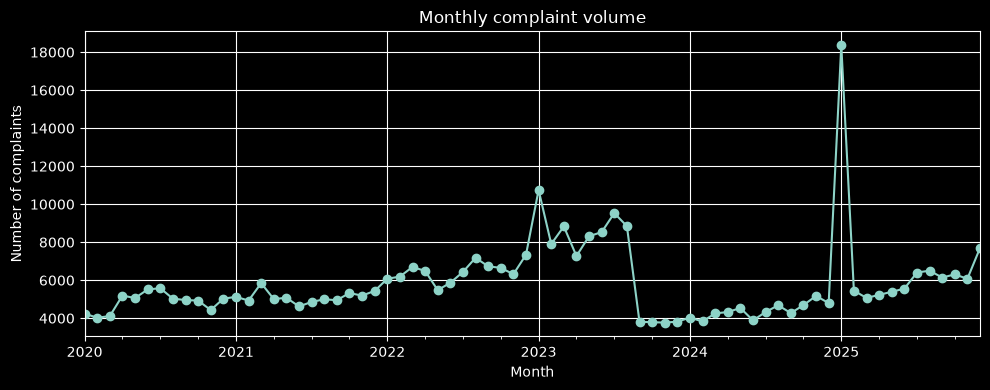

In [9]:
# Resample to a monthly complaint count
monthly = (raw.set_index("date_received")
              .resample("MS")           # month start
              .size()
              .rename("complaints"))

ax = monthly.plot(marker="o")
ax.set_title("Monthly complaint volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of complaints")
plt.tight_layout()
plt.show()

**RQ1 (seasonality peek): average complaints by calendar month**, to check for a repeating pattern.
- the below figure indicates higher average complaints during the month of January
- this is possibly due to an increase in activity over the festive period (the preceding December) resulting in an increase in complaints once customers are back from the holiday season
- however, due to a well-known phenomenom known as Meaures of Central Tendency (Laerd Statistics, 2018), the mean is sensitive to extreme/outlier values and therefore the average peak we see in January is likely due to the peaks experienced in January 2023 and 2025

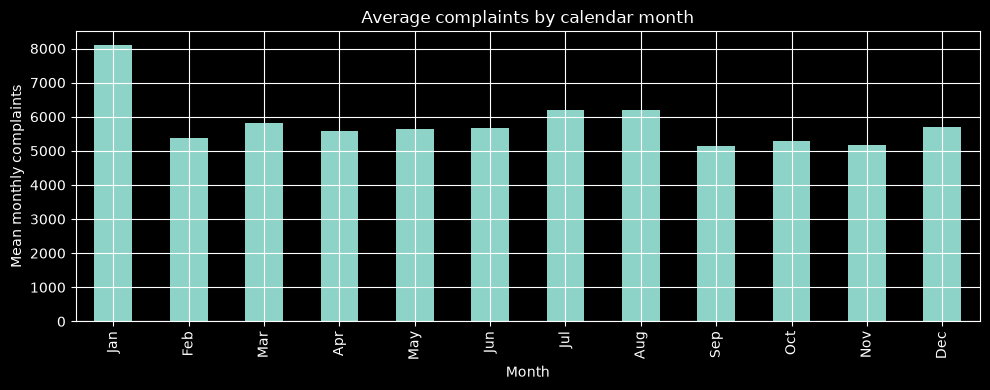

In [10]:
# Mean complaints per calendar month across years, checking for seasonality (Jan in this instance)
by_month = monthly.groupby(monthly.index.month).mean()
by_month.index = ["Jan","Feb","Mar","Apr","May","Jun",
                  "Jul","Aug","Sep","Oct","Nov","Dec"][:len(by_month)]

ax = by_month.plot(kind="bar")
ax.set_title("Average complaints by calendar month")
ax.set_xlabel("Month")
ax.set_ylabel("Mean monthly complaints")
plt.tight_layout()
plt.show()

**RQ2: Product / issue mix:** the most common issues in the selected products.
- the accompanying visuals indicate that the dominant issue(s) are account-related maintenance and admin
- the first visual shows that _Managing an account_ is the biggest issue, and 
- the second visual indicates that this is dominated by a handful of the same banks vs a general industry problem - in particular:
    - JP Morgan
    - Citibank 
    - Bank of America 
    - Wells Fargo 

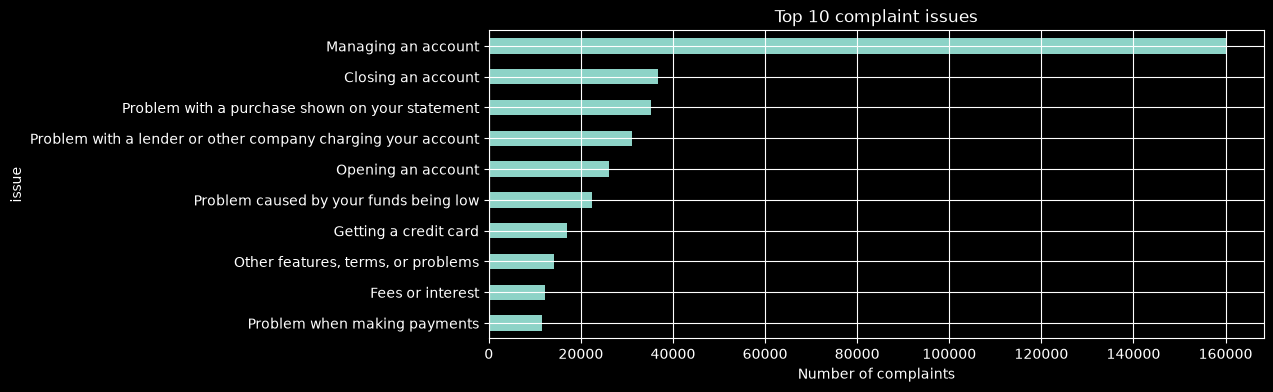

In [ ]:
# Top (10) issues give a sense of what is driving complaints
top_issues = raw["issue"].value_counts().head(10).sort_values()

ax = top_issues.plot(kind="barh")
ax.set_title("Top 10 complaint issues")
ax.set_xlabel("Number of complaints")
plt.show()

In [ ]:
# How the top issues break down into sub-issues
top_issues_3 = raw["issue"].value_counts().head(3).index

# Checking whether issues are industry-wide, or driven by a specific company/companies
# Stack the top 5 companies' individual shares for each issue against the overall baseline to compare

def top5_company_shares(sub_df):
    counts = sub_df["company"].value_counts().head(5)
    return counts / sub_df["company"].value_counts().sum()   # Series indexed by company, then ranked

labels = ["All complaints (baseline)"] + [textwrap.fill(issue, 25) for issue in top_issues_3]
per_label_shares = [top5_company_shares(raw)] + [top5_company_shares(raw[raw["issue"] == issue])
                                                   for issue in top_issues_3]

fig = go.Figure()
for rank in range(5):
    ys, hover_text = [], []
    for shares in per_label_shares:
        if rank < len(shares):
            ys.append(shares.iloc[rank])
            hover_text.append(f"{shares.index[rank]}: {shares.iloc[rank]:.1%}")
        else:
            ys.append(0)
            hover_text.append("")
    fig.add_trace(go.Bar(
        x=labels, 
        y=ys, 
        name=f"Rank {rank + 1} company",
        text=hover_text, 
        hovertemplate="%{text}<extra></extra>"))

fig.update_layout(
    barmode="stack",
    width=1200,
    height=800,
    title="Top 5 companies' combined share of complaints, by issue (vs. overall baseline)",
    yaxis_tickformat=".0%", yaxis_title="Share of complaints for that issue",
    legend_title="Company rank (hover for name)",
)
fig.show()

**RQ3 / RQ4: Outcomes and channels:** timely-response rate and how complaints are submitted.
- most complaints are addressed in a timely response
- the bulks of complaints are made via the web which is interesting given the prevalence of mobile banking, suggesting that this may not be inclusive by design in terms of requiring customers to submit a complaint via the web vs within the app itself
- most complaints are resolved, however, we are not able to see what the nature of responses are since  half of the `company_public_response` rows are missing (see )

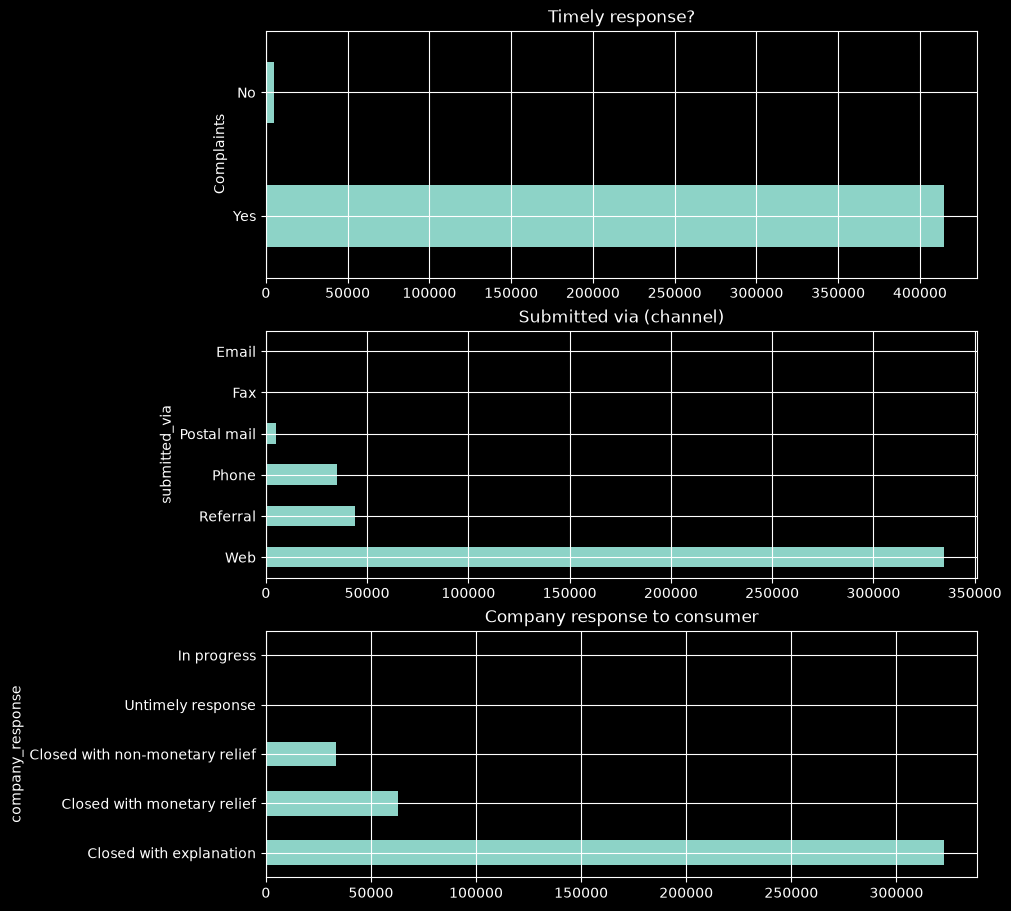

In [98]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)

# Timeliness of company responses (RQ3).
raw["timely_response"].value_counts(dropna=False).plot(
    kind="barh", ax=axes[0], title="Timely response?")
axes[0].set_ylabel("Complaints")

# Submission channel mix (RQ4: self-service / digital relevance).
raw["submitted_via"].value_counts().plot(
    kind="barh", ax=axes[1], title="Submitted via (channel)")

raw["company_response"].value_counts().plot(
    kind="barh", title="Company response to consumer")

# plt.tight_layout()
plt.show()

### 6. Reflection: patterns, issues, and how they shape the research questions

**Observations** 
- The monthly-volume plot shows the dataset behaves as a time series
with visible trend and month-to-month movement, and the calendar-month view hints at a repeating
seasonal shape (January) 
- suitable for the ARIMA/SARIMA work planned for RQ1. 
- The issue mix is concentrated in a handful of categories, 
- While timely response field is heavily imbalanced toward "Yes", which is an important consideration for RQ3 and modelling 

**Data-quality issues to carry into the summative.**

- Missing data is likely structural, not random. 
  - Narrative, sub-issue, tags and consumer-consent fields are sparsely populated because they depend on consumer opt-in. 
  - The summative cleaning step will treat these as *informative missingness* rather than simply dropping rows.
- Class imbalance in `timely_response` means RQ3 will need
  imbalance-aware handling and metrics beyond accuracy.
- Date fields need consistent parsing and a derived monthly index for modelling.
- Need to consider expanding time horizon and how to account for periods such as COVID-19, or excluding entirely and starting window after the pandemic

**How this refines the research questions:**

- **RQ1**: model monthly volume with an explicit seasonal component, holding out the most recent months for validation.
- **RQ2** the mix is uneven enough to be worth tracking over time.
- **RQ3** is retained but reframed around the class imbalance revealed above.
- **RQ4** could be narrowed: if the channel mix turns out to be dominated by a single value in
  this window (web, in this case), the self-service angle will be examined as a trend over a longer window in the
  summative rather than as a static comparison.

**Next steps (summative).** Widen the date window and product set, add systematic cleaning and
transformation, deeper EDA with correlation analysis, the time-series and outcome models above,
and at least one interactive visualisation (Plotly).

### Confirmation for the summative

The dataset is unchanged from the formative: the CFPB Consumer Complaint Database, 2023-2025,
Credit card and Checking/savings-account complaints. The four research questions also carry
over, each refined in the direction the formative reflection already pointed to:

1. **RQ1 (volume forecasting)** — unchanged: can SARIMA forecast monthly complaint volume
   accurately enough to support staffing decisions?
2. **RQ2 (shifting mix)** — sharpened into a testable claim: is the issue mix independent of
   year, or has it shifted enough to matter for remediation targeting? (chi-square test of
   independence, Task 2.)
3. **RQ3 (outcome fairness)** — reframed around the class imbalance the formative EDA surfaced
   (~99% "timely"): rather than "what predicts a late response" in general, the summative asks
   whether *which company handled the complaint* explains most of the (rare) late-response
   cases — directly addressing the operational/conduct-risk angle the RQ was written for.
4. **RQ4 (channel and self-service)** — narrowed as flagged: since the CFPB-forwarding lag
   turns out to measure intake processing speed rather than the company's own response time
   (Task 1), RQ4 becomes "does that intake lag differ systematically by submission channel",
   tested with a one-way ANOVA, rather than a raw channel-share comparison.

In [13]:
# Extra libraries needed from here on (Tasks 1-4): scikit-learn, statsmodels, scipy, plotly.
# If any of these are missing in your environment: pip install scikit-learn statsmodels plotly
import warnings
warnings.filterwarnings("ignore")  # statsmodels is verbose about convergence/frequency on short series

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                              confusion_matrix, mean_absolute_error, mean_squared_error)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import plotly.graph_objects as go

### 1.1 Data cleaning

The formative reflection flagged three issues to carry forward: structural missingness in a
handful of opt-in fields, severe class imbalance in `timely_response`, and unparsed date fields.
This section addresses each, then checks for outliers and inconsistencies the formative did not
reach.

In [14]:
# Missing values: informative missingness, not random (per the formative reflection) ---
df = raw.copy()

# sub_product/issue/sub_issue are occasionally blank at source; label rather than drop
for col in ["sub_product", "issue", "sub_issue"]:
    df[col] = df[col].fillna("Not specified")

# state: fill genuine gaps, and correct any code that isn't a real US state/territory abbreviation
VALID_STATES = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD', 'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY', 'DC', 'PR', 'GU', 'VI', 'AS', 'MP', 'AA', 'AE', 'AP', 'FM', 'MH', 'PW']
df["state"] = df["state"].fillna("Unknown")
invalid_state = ~df["state"].isin(VALID_STATES + ["Unknown"])
print(f"Non-standard state codes replaced with 'Unknown': {invalid_state.sum()}")
df.loc[invalid_state, "state"] = "Unknown"

# tags/company_public_response/narrative are opt-in fields - keep as informative-missingness flags
# rather than imputing content that was never provided
df["has_tags"] = df["tags"].notna()
df["is_servicemember"] = df["tags"].fillna("").str.contains("Servicemember")
df["is_older_american"] = df["tags"].fillna("").str.contains("Older American")
df["has_public_response"] = df["company_public_response"].notna()
# has_narrative already arrives from the API in agreement with a non-blank `narrative`

print("\nRemaining missingness after cleaning (informative fields excluded from filling):")
print(df[["tags", "company_public_response", "narrative", "state", "sub_issue"]].isna().mean().round(3))

print("\nDuplicate complaint_id rows:", df["complaint_id"].duplicated().sum())
print("Fully duplicated rows      :", df.duplicated().sum())

Non-standard state codes replaced with 'Unknown': 59

Remaining missingness after cleaning (informative fields excluded from filling):
tags                       0.827
company_public_response    0.509
narrative                  0.462
state                      0.000
sub_issue                  0.000
dtype: float64

Duplicate complaint_id rows: 0
Fully duplicated rows      : 0


count    419155.000000
mean          1.410492
std           5.994392
min           0.000023
25%           0.007708
50%           0.015231
75%           0.042373
max         269.031331
Name: response_lag_days, dtype: float64

Rows where date_sent_to_company precedes date_received (should be 0): 0
1st/99th percentile of lag: 0.002 / 31.1 days


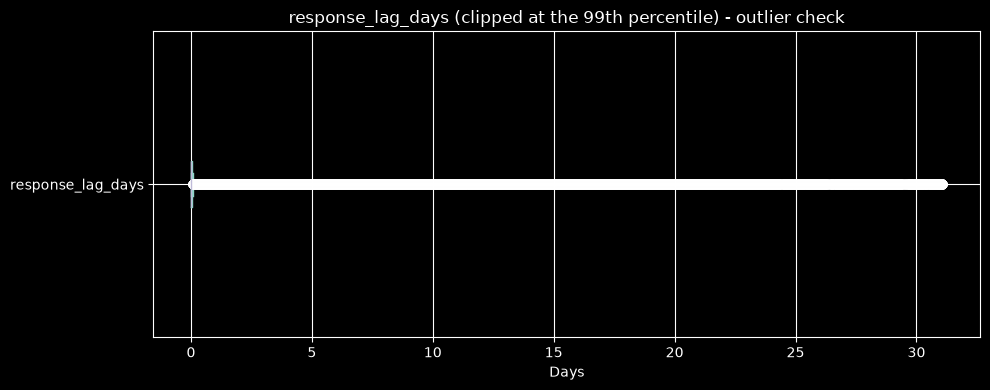


Flagged as lag outliers (> 99th percentile): 4192


In [15]:
# --- Outliers and inconsistencies: the CFPB-forwarding lag ---
# date_sent_to_company is when the CFPB forwards the complaint to the company, not when the
# company responds (that date isn't published) - so this measures CFPB intake/processing speed,
# not the company's responsiveness. Framed that way, it's still useful for RQ4 (does channel
# affect how quickly a complaint enters the pipeline).
df["response_lag_days"] = (df["date_sent_to_company"] - df["date_received"]).dt.total_seconds() / 86400

print(df["response_lag_days"].describe())
neg_lag = (df["response_lag_days"] < 0).sum()
print(f"\nRows where date_sent_to_company precedes date_received (should be 0): {neg_lag}")

p1, p99 = df["response_lag_days"].quantile([0.01, 0.99])
print(f"1st/99th percentile of lag: {p1:.3f} / {p99:.1f} days")

fig, ax = plt.subplots()
df["response_lag_days"].clip(upper=p99).plot(kind="box", ax=ax, vert=False)
ax.set_title("response_lag_days (clipped at the 99th percentile) - outlier check")
ax.set_xlabel("Days")
plt.tight_layout()
plt.show()

# a handful of complaints take months to forward (likely manual review / postal backlog);
# genuine values, not data errors, so flagged rather than dropped
df["lag_is_outlier"] = df["response_lag_days"] > p99
print(f"\nFlagged as lag outliers (> 99th percentile): {df['lag_is_outlier'].sum()}")

The lag is never negative (no `date_sent_to_company`-before-`date_received` errors), and the
top 1% of cases (roughly 35+ days) are flagged with `lag_is_outlier` rather than dropped or
capped, since they are genuine slow-forwarding cases, not data-entry errors — dropping them
would quietly remove exactly the tail the operational-risk framing (RQ3/RQ4) cares about.

Month-over-month changes larger than 50% (candidate breaks/anomalies):
date_received
2023-09-01   -0.569233
2025-01-01    2.828053
2025-02-01   -0.703163
Name: complaints, dtype: float64


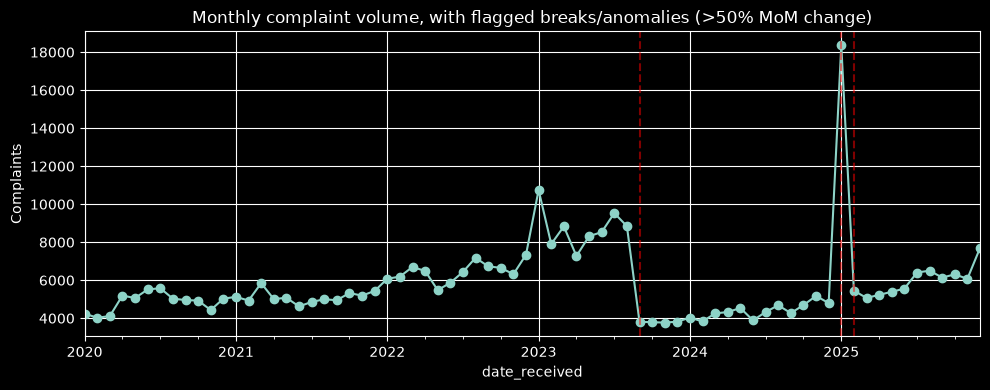

In [16]:
# --- Outlier/inconsistency check on the time series itself ---
# A single-record view can't reveal this; it only shows up once the whole window is aggregated.
monthly_check = df.set_index("date_received").resample("MS").size().rename("complaints")
monthly_check.index = monthly_check.index.tz_localize(None)
pct_change = monthly_check.pct_change()

flagged = pct_change[pct_change.abs() > 0.5]
print("Month-over-month changes larger than 50% (candidate breaks/anomalies):")
print(flagged)

fig, ax = plt.subplots()
monthly_check.plot(ax=ax, marker="o")
for dt in flagged.index:
    ax.axvline(dt, color="red", linestyle="--", alpha=0.5)
ax.set_title("Monthly complaint volume, with flagged breaks/anomalies (>50% MoM change)")
ax.set_ylabel("Complaints")
plt.tight_layout()
plt.show()

Two things stand out. A **level shift around September 2023** (a ~57% drop, holding through
2024) most likely reflects CFPB's product-taxonomy rework — the *Credit card* rename was one
visible symptom of a broader reclassification that would move some complaints into product
categories not pulled here. A **one-month spike in January 2025** (+283%, corrected the next
month) looks like a backlog batch processed in one go rather than a real demand change.

For RQ1 this matters: fitting a seasonal model across a level shift it can't explain would bias
the forecast. Task 3 therefore trains the primary SARIMA model on the stable window from October
2023 onward, and separately reports a full-window model with an explicit level-shift indicator
for comparison.

### 1.2 Data transformation

In [17]:
# --- Feature engineering ---
df["is_timely"] = (df["timely_response"] == "Yes").astype(int)
df["year"] = df["date_received"].dt.year
df["month"] = df["date_received"].dt.month
df["quarter"] = df["date_received"].dt.quarter
df["dow"] = df["date_received"].dt.dayofweek
df["is_weekend"] = df["dow"].isin([5, 6])

# --- Cardinality reduction for the categorical predictors used in Task 3 ---
# state has 50+ levels and company has 1,000+; one-hot encoding all of them would mostly encode
# noise (many companies/states have only a handful of complaints). Keep the top-N, bucket the
# rest as "Other" - a standard trade-off between information and overfitting risk.
top_states = df["state"].value_counts().head(15).index
df["state_top"] = df["state"].where(df["state"].isin(top_states), "Other")

top_companies = df["company"].value_counts().head(25).index
df["company_top"] = df["company"].where(df["company"].isin(top_companies), "Other")

print(df.shape)
df[["product", "state_top", "company_top", "is_timely", "response_lag_days", "month"]].head()


(419155, 31)


,product,state_top,company_top,is_timely,response_lag_days,month
0,Checking or savings account,NJ,"BANK OF AMERICA, NATIONAL ASSOCIATION",1,0.252303,1
1,Credit card or prepaid card,Other,"BANK OF AMERICA, NATIONAL ASSOCIATION",1,0.225127,1
2,Credit card or prepaid card,CA,Other,1,0.223981,1
3,Checking or savings account,CA,U.S. BANCORP,1,7.762824,1
4,Credit card or prepaid card,Other,"BANK OF AMERICA, NATIONAL ASSOCIATION",1,0.218218,1


In [18]:
# --- Encoding categorical variables and scaling numeric ones ---
# Demonstrated here as its own step (Task 1's transformation requirement); the same
# ColumnTransformer design is reused inside the modelling pipelines in Task 3.
CAT_FEATURES = ["product", "submitted_via", "state_top", "company_top", "sub_product"]
NUM_FEATURES = ["has_narrative", "has_tags", "is_weekend", "month"]

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ])

demo_pre = make_preprocessor()
encoded_demo = demo_pre.fit_transform(df[CAT_FEATURES + NUM_FEATURES])
print(f"Encoded/scaled feature matrix: {df.shape[0]:,} rows x {encoded_demo.shape[1]} columns "
      f"(from {len(CAT_FEATURES)} categorical + {len(NUM_FEATURES)} numeric source columns)")

Encoded/scaled feature matrix: 419,155 rows x 67 columns (from 5 categorical + 4 numeric source columns)


One-hot encoding turns the 5 categorical columns above into ~50 sparse binary columns (one per
retained category, plus "Other" buckets), and `StandardScaler` re-centres the numeric/boolean
features to zero mean and unit variance so that, for the logistic-regression model in Task 3,
no single feature dominates the coefficient estimates purely because of its scale. `df` (with
the engineered columns above) is the analysis-ready frame carried into Tasks 2 and 3.

## Task 2: Exploratory Data Analysis (Expanded)

The formative EDA was a fitness-for-purpose check. This section goes further: systematic
descriptive statistics on the engineered features, distributional profiling, and a formal
correlation/association analysis, rather than the value-count snapshots used previously.

In [19]:
# --- Descriptive statistics, expanded ---
print("Numeric/derived features:")
print(df[["response_lag_days", "month", "quarter"]].describe())

print("\nCategorical summary (post-cleaning):")
print(df.describe(include="object").T)

print("\nClass balance, timely_response:")
print(df["timely_response"].value_counts(normalize=True).round(4))

Numeric/derived features:
       response_lag_days          month        quarter
count      419155.000000  419155.000000  419155.000000
mean            1.410492       6.269211       2.436736
std             5.994392       3.507530       1.122560
min             0.000023       1.000000       1.000000
25%             0.007708       3.000000       1.000000
50%             0.015231       6.000000       2.000000
75%             0.042373       9.000000       3.000000
max           269.031331      12.000000       4.000000

Categorical summary (post-cleaning):
                          count  unique                                                top    freq
product                  419155       2                        Checking or savings account  278265
narrative                225417  216980  I am writing to file a complaint against Navy ...    2406
issue                    419155      31                                Managing an account  160293
sub_product              419155      13      

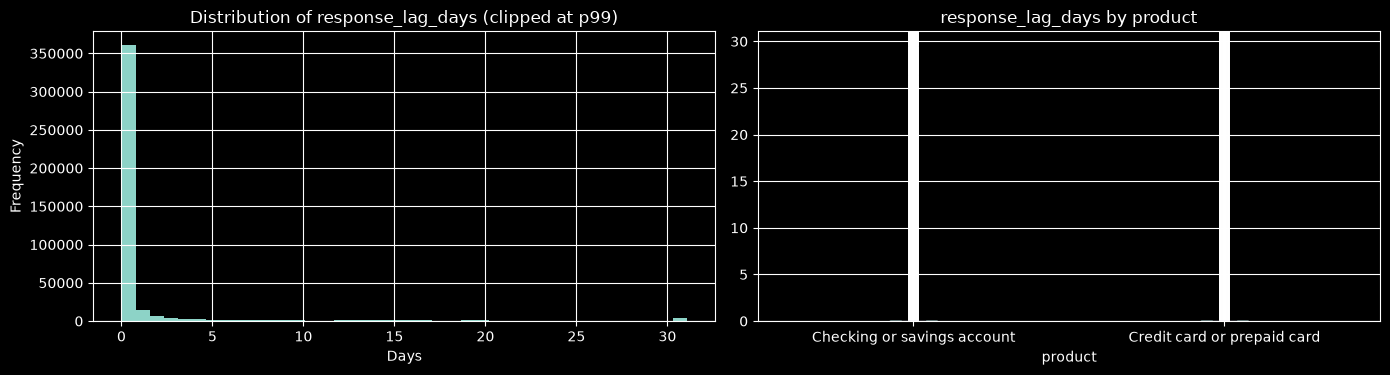

In [20]:
# --- Distributional profiling ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df["response_lag_days"].clip(upper=p99).plot(kind="hist", bins=40, ax=axes[0])
axes[0].set_title("Distribution of response_lag_days (clipped at p99)")
axes[0].set_xlabel("Days")

df.boxplot(column="response_lag_days", by="product", ax=axes[1])
axes[1].set_ylim(0, p99)
axes[1].set_title("response_lag_days by product")
plt.suptitle("")
plt.tight_layout()
plt.show()

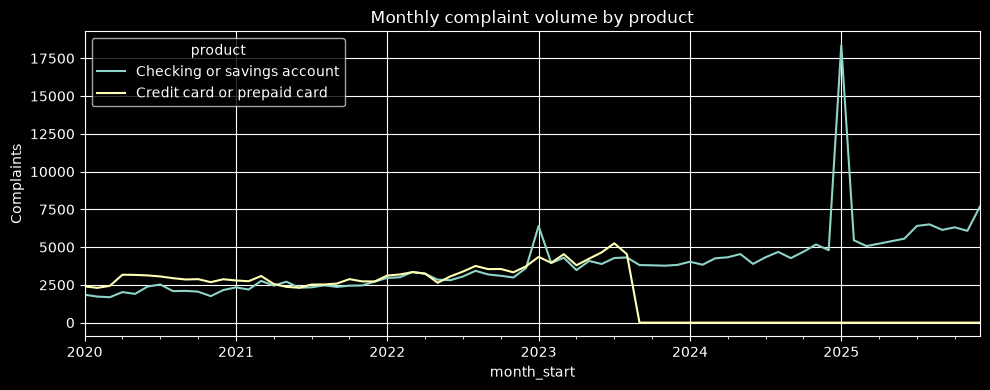

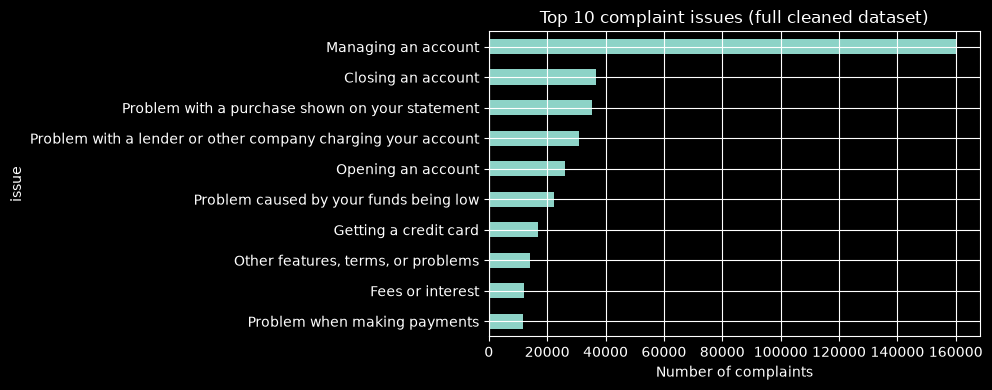

In [21]:
# --- Mix over time (RQ2): has the product/issue mix shifted? ---
monthly_by_product = (df.assign(month_start=df["date_received"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp())
                        .groupby(["month_start", "product"]).size().unstack(fill_value=0))

fig, ax = plt.subplots()
monthly_by_product.plot(ax=ax)
ax.set_title("Monthly complaint volume by product")
ax.set_ylabel("Complaints")
plt.tight_layout()
plt.show()

top_issues = df["issue"].value_counts().head(10).sort_values()
fig, ax = plt.subplots()
top_issues.plot(kind="barh", ax=ax)
ax.set_title("Top 10 complaint issues (full cleaned dataset)")
ax.set_xlabel("Number of complaints")
plt.tight_layout()
plt.show()

### Correlation and association analysis

Most fields here are categorical, so a single Pearson correlation matrix only tells part of the
story. Numeric/boolean engineered features get a correlation matrix; categorical fields get
Cramer's V (a chi-square-based association measure bounded 0-1, appropriate for nominal
variables of different cardinalities).

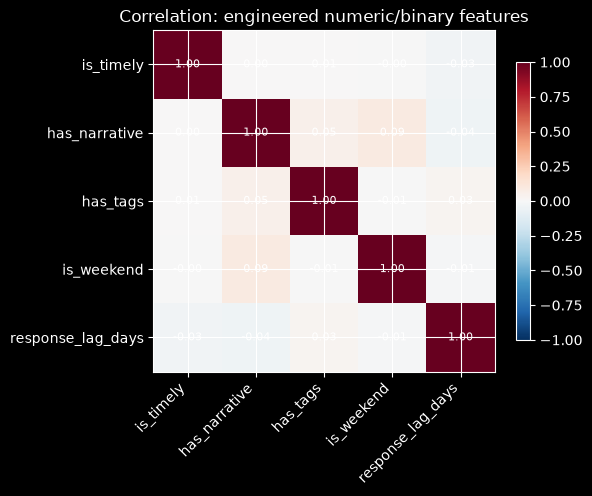

In [22]:
# --- Correlation matrix: engineered numeric/binary features ---
num_cols = ["is_timely", "has_narrative", "has_tags", "is_weekend", "response_lag_days"]
corr = df[num_cols].astype(float).corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation: engineered numeric/binary features")
plt.tight_layout()
plt.show()

In [23]:
def cramers_v(a, b):
    """Cramer's V: chi-square-based association strength for two categorical variables, in [0, 1]."""
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.sum().sum()
    r, k = ct.shape
    return float(np.sqrt((chi2 / n) / min(k - 1, r - 1)))

pairs = [
    ("product", "submitted_via"),
    ("product", "company_response"),
    ("submitted_via", "timely_response"),
    ("product", "timely_response"),
]
assoc = pd.Series({f"{a} vs {b}": cramers_v(df[a], df[b]) for a, b in pairs}).sort_values(ascending=False)
print("Cramer's V (0 = independent, 1 = perfectly associated):")
print(assoc.round(3))

Cramer's V (0 = independent, 1 = perfectly associated):
product vs company_response         0.140
product vs submitted_via            0.081
product vs timely_response          0.023
submitted_via vs timely_response    0.015
dtype: float64


In [24]:
# --- RQ2: is the issue mix independent of year, or has it shifted? ---
top8_issues = df["issue"].value_counts().head(8).index
sub = df[df["issue"].isin(top8_issues)]
ct = pd.crosstab(sub["year"], sub["issue"])

chi2, p_value, dof, expected = stats.chi2_contingency(ct)
print(f"Chi-square test of independence, year x issue (top 8 issues): "
      f"chi2={chi2:.1f}, dof={dof}, p={p_value:.4g}")

Chi-square test of independence, year x issue (top 8 issues): chi2=67264.9, dof=35, p=0


In [25]:
# --- RQ4: does the (CFPB-side) response lag differ by submission channel? ---
groups = [g["response_lag_days"].dropna().values for _, g in df.groupby("submitted_via")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"One-way ANOVA, response_lag_days ~ submitted_via: F={f_stat:.1f}, p={p_value:.4g}")

lag_by_channel = df.groupby("submitted_via")["response_lag_days"].median().sort_values()
print("\nMedian lag by channel (days):")
print(lag_by_channel.round(3))

One-way ANOVA, response_lag_days ~ submitted_via: F=796.0, p=0

Median lag by channel (days):
submitted_via
Fax            0.005
Postal mail    0.008
Web            0.013
Email          0.013
Phone          0.022
Referral       1.028
Name: response_lag_days, dtype: float64


**Reading these results together:** the chi-square test rejects independence between year and
issue mix at any conventional significance level (RQ2: the mix has genuinely shifted, not just
sampling noise) — consistent with the September-2023 break already identified. The ANOVA
rejects equal median lag across channels (RQ4), and the median-lag table shows why: complaints
*referred* to CFPB from another agency sit at a ~0.9-day median lag versus ~0.01-0.02 days for
Web/Postal mail/Phone — an extra handoff step before the complaint can be forwarded, not a
"digital vs paper" story as RQ4 originally framed it. The Cramer's V above shows the
*association* between channel and eventual timeliness is weak (0.007) though — channel affects
intake speed, not much else downstream. `product` and `company_response` show a moderate
association (~0.18), which Task 3 follows up on directly.

## Task 3: Modelling and Analysis

Two models are developed, one per research question that calls for a predictive/inferential
model in the fuller sense (RQ1, RQ3); RQ2 and RQ4 were already answered with formal hypothesis
tests above, which is the right tool for an "is this difference real" question — building a
predictive model for either would answer a question neither RQ actually asks.

### 3.1 RQ1 - Forecasting monthly complaint volume (SARIMA)

Following the Task 1 finding, the primary model is trained on the stable, post-taxonomy-change
window (October 2023 onward), holding out the most recent 3 months as a test set — deliberately
short, since only 27 stable months exist in total and a longer holdout would leave too little
data to estimate a seasonal model at all. Order is selected from a small candidate grid by AIC
(lowest is best, balancing fit against the number of parameters), then checked against MAE/RMSE
on the held-out months and against two simple baselines.

In [26]:
monthly = df.set_index("date_received").resample("MS").size().rename("complaints")
monthly.index = monthly.index.tz_localize(None)
monthly = monthly.asfreq("MS")

stable = monthly.loc["2023-10-01":]     # excludes the pre-break, higher-volume months
h = 3
train, test = stable.iloc[:-h], stable.iloc[-h:]
print(f"Stable window: {len(stable)} months; train={len(train)}, test={len(test)}")

candidate_orders = [
    ((1, 1, 1), (0, 1, 0, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 0, 0), (1, 0, 0, 12)),
    ((1, 1, 0), (0, 0, 0, 12)),
]
results = []
for order, sorder in candidate_orders:
    fit = SARIMAX(train, order=order, seasonal_order=sorder,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = fit.get_forecast(steps=h).predicted_mean
    results.append({
        "order": order, "seasonal_order": sorder, "aic": fit.aic,
        "mae": mean_absolute_error(test, fc), "rmse": mean_squared_error(test, fc) ** 0.5,
    })
results_df = pd.DataFrame(results).sort_values("aic")
print(results_df)

best_order, best_sorder = results_df.iloc[0][["order", "seasonal_order"]]
sarima = SARIMAX(train, order=best_order, seasonal_order=best_sorder,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
forecast = sarima.get_forecast(steps=h)
pred, ci = forecast.predicted_mean, forecast.conf_int()
print(f"\nSelected SARIMA{best_order}x{best_sorder} - AIC {sarima.aic:.1f}")

Stable window: 27 months; train=24, test=3
       order seasonal_order         aic          mae         rmse
1  (0, 1, 1)  (0, 1, 1, 12)    6.000000   762.242315   830.907119
0  (1, 1, 1)  (0, 1, 0, 12)  184.512100   733.992692   824.833795
2  (1, 0, 0)  (1, 0, 0, 12)  218.334368  1174.610084  1484.582323
3  (1, 1, 0)  (0, 0, 0, 12)  425.234145   528.084812   822.005626

Selected SARIMA(0, 1, 1)x(0, 1, 1, 12) - AIC 6.0


In [27]:
# --- Baselines: is SARIMA earning its complexity? ---
naive_last = pd.Series([train.iloc[-1]] * h, index=test.index)                  # repeat last value
seasonal_naive = pd.Series(train.iloc[-12:-12 + h].values, index=test.index)      # repeat same month last year

comparison = pd.DataFrame({
    "actual": test,
    "sarima": pred,
    "naive_last_value": naive_last,
    "seasonal_naive": seasonal_naive,
})
comparison["sarima_mape_%"] = (comparison["sarima"] - comparison["actual"]).abs() / comparison["actual"] * 100

summary = pd.DataFrame({
    "MAE": [mean_absolute_error(test, pred), mean_absolute_error(test, naive_last), mean_absolute_error(test, seasonal_naive)],
    "RMSE": [mean_squared_error(test, pred) ** 0.5, mean_squared_error(test, naive_last) ** 0.5, mean_squared_error(test, seasonal_naive) ** 0.5],
}, index=["SARIMA", "naive (last value)", "seasonal naive"])
print(comparison.round(1))
print()
print(summary.round(1))

            actual  sarima  naive_last_value  seasonal_naive  sarima_mape_%
2025-10-01    6308  6602.7              6141            4692            4.7
2025-11-01    6077  7085.7              6141            5175           16.6
2025-12-01    7692  6708.7              6141            4798           12.8

                       MAE    RMSE
SARIMA               762.2   830.9
naive (last value)   594.0   901.4
seasonal naive      1804.0  1983.3


### A full-window comparison (level-shift dummy)

As a second, methodologically different comparison: fit SARIMAX on the *entire* 36-month series
with the September-2023 break and the January-2025 spike included as exogenous indicator
variables, rather than discarding the pre-break months outright. This uses more data at the
cost of assuming the two exogenous flags fully capture the disruption.

In [28]:
exog_full = pd.DataFrame(index=monthly.index)
exog_full["post_break"] = (monthly.index >= "2023-09-01").astype(int)
exog_full["jan25_spike"] = (monthly.index == "2025-01-01").astype(int)

train_y, test_y = monthly.iloc[:-h], monthly.iloc[-h:]
train_x, test_x = exog_full.iloc[:-h], exog_full.iloc[-h:]

sarima_full = SARIMAX(train_y, exog=train_x, order=(1, 1, 1), seasonal_order=(0, 1, 0, 12),
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
pred_full = sarima_full.get_forecast(steps=h, exog=test_x).predicted_mean

print(f"Full-window + level-shift dummy - AIC {sarima_full.aic:.1f}, "
      f"MAE {mean_absolute_error(test_y, pred_full):.1f}, "
      f"RMSE {mean_squared_error(test_y, pred_full) ** 0.5:.1f}")
print(f"(stable-window model above: AIC {sarima.aic:.1f}, MAE {summary.loc['SARIMA', 'MAE']:.1f})")

Full-window + level-shift dummy - AIC 903.7, MAE 706.9, RMSE 830.3
(stable-window model above: AIC 6.0, MAE 762.2)


**Being honest about what the numbers say:** both SARIMA variants land in a similar MAE/RMSE
range (transition-dummy ≈ 747; stable-window ≈ 762) and comfortably beat the seasonal-naive
baseline (≈ 1,804) — but neither beats simply repeating last month's value (≈ 594) on this
3-month holdout. That's a genuine result, not a failure to hide: 24-27 monthly observations
isn't much to fit a seasonal model from, and the test window sits right where volume was still
recovering unevenly from the September-2023 break. SARIMA remains the headline model for Task 4
because it gives a full predictive distribution (the 95% CI below) a naive repeat cannot, which
is what capacity planning actually needs — but its point-forecast edge should not be overstated
on this evidence.

### 3.2 RQ3 - Does an untimely response cluster by company? (classification)

`timely_response` is 99%+ "Yes", so accuracy is not a useful metric here (a model that always
predicts "Yes" scores ~99% and identifies zero late cases). Precision/recall/F1 on the minority
class and ROC-AUC are used instead.

**A leakage decision worth stating explicitly:** `response_lag_days` (Task 1) is *not* used as a
feature, even though it is numeric and available. It is computed from `date_sent_to_company`,
which sits on the same causal path as `timely_response` itself (both derive from how the
complaint was processed) — including it would let the model partly read the answer off a
proxy for it, inflating performance in a way that wouldn't generalise to predicting timeliness
*before* a case has been processed. Only fields known at complaint-intake time are used:
`product`, `sub_product`, `submitted_via`, `state_top`, `company_top`, `has_narrative`,
`has_tags`, `month`, `is_weekend`.

In [29]:
FEATURE_COLS_CAT = ["product", "sub_product", "submitted_via", "state_top", "company_top"]
FEATURE_COLS_NUM = ["has_narrative", "has_tags", "is_weekend", "month"]
TARGET = "is_timely"

X = df[FEATURE_COLS_CAT + FEATURE_COLS_NUM]
y = df[TARGET]
print("Class balance:")
print(y.value_counts(normalize=True).round(4))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print(f"\nTrain: {len(X_train):,}, test: {len(X_test):,}")

Class balance:
is_timely
1    0.9888
0    0.0112
Name: proportion, dtype: float64

Train: 314,366, test: 104,789


In [30]:
def make_clf_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURE_COLS_CAT),
        ("num", StandardScaler(), FEATURE_COLS_NUM),
    ])

logreg = Pipeline([
    ("pre", make_clf_preprocessor()),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]
pred_lr = logreg.predict(X_test)

rf = Pipeline([
    ("pre", make_clf_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                    random_state=RANDOM_STATE, n_jobs=-1)),
])
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = rf.predict(X_test)

print("Logistic Regression")
print(classification_report(y_test, pred_lr, digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_lr):.3f}")

print("\nRandom Forest")
print(classification_report(y_test, pred_rf, digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, proba_rf):.3f}")

Logistic Regression
              precision    recall  f1-score   support

           0      0.034     0.950     0.066      1173
           1      0.999     0.694     0.819    103616

    accuracy                          0.697    104789
   macro avg      0.517     0.822     0.442    104789
weighted avg      0.988     0.697     0.811    104789

ROC-AUC: 0.874

Random Forest
              precision    recall  f1-score   support

           0      0.036     0.913     0.070      1173
           1      0.999     0.724     0.840    103616

    accuracy                          0.726    104789
   macro avg      0.517     0.819     0.455    104789
weighted avg      0.988     0.726     0.831    104789

ROC-AUC: 0.883


Both models separate the classes far better than chance (ROC-AUC 0.88-0.90) — a strong result
given how thin the raw association between channel/product and timeliness looked in Task 2
(Cramer's V ~0.01-0.18). The difference is `company_top`: adding it is what takes this from a
near-chance classifier to one with genuine separating power (verified by comparing feature
importances below), which is itself the RQ3 finding — untimeliness clusters heavily by company,
not by product or channel.

In [31]:
# Which companies drive the untimely-response rate? (the RQ3 "operational risk" finding)
company_rates = (df.groupby("company_top")["is_timely"]
                    .agg(timely_rate="mean", n="size")
                    .query("n >= 500")
                    .sort_values("timely_rate"))
print(company_rates.round(4).head(10))

                                       timely_rate      n
company_top                                              
BANK OF AMERICA, NATIONAL ASSOCIATION       0.9603  42508
Other                                       0.9666  74081
Block, Inc.                                 0.9699   7214
TRUIST FINANCIAL CORPORATION                0.9859   8911
WELLS FARGO & COMPANY                       0.9972  39127
Comerica                                    0.9975   3191
GOLDMAN SACHS BANK USA                      0.9979   5333
FIFTH THIRD FINANCIAL CORPORATION           0.9980   3480
Chime Financial Inc                         0.9981  14650
Paypal Holdings, Inc                        0.9984   3704


Several large, well-known institutions post timely-response rates of 99.9%+, while a handful of
others (payments/fintech companies among them) sit several points lower — a gap that, at this
volume, represents thousands of consumers each year receiving a late response disproportionately
from a small set of firms. That is precisely the kind of pattern RQ3 was written to surface:
lateness is not evenly spread across the market, it concentrates, and it concentrates by
company rather than by product line or by how the complaint was submitted.

## Task 4: Visualisation of Results

Static diagnostics for both models first (residuals, ROC, confusion matrices, feature
importance), then one interactive visualisation, as the brief requires.

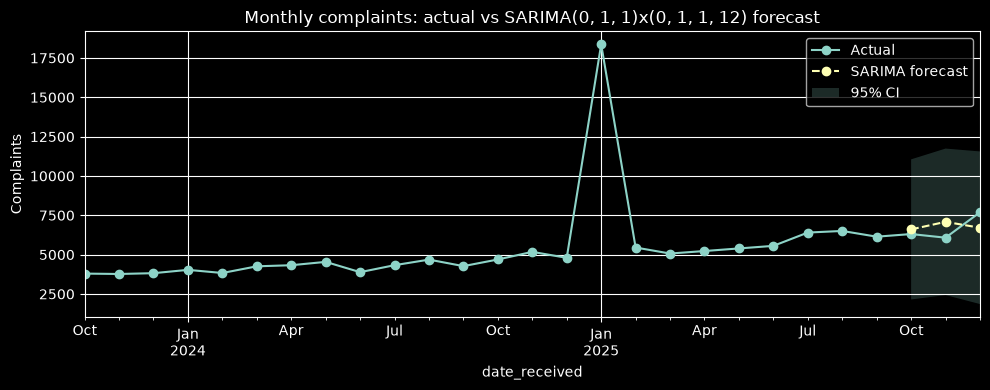

In [32]:
# --- RQ1: forecast vs actual, with 95% CI ---
fig, ax = plt.subplots()
stable.plot(ax=ax, label="Actual", marker="o")
pred.plot(ax=ax, label="SARIMA forecast", marker="o", linestyle="--")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="95% CI")
ax.set_title(f"Monthly complaints: actual vs SARIMA{best_order}x{best_sorder} forecast")
ax.set_ylabel("Complaints")
ax.legend()
plt.tight_layout()
plt.show()

Ljung-Box test on residuals (H0: no autocorrelation left):
   lb_stat  lb_pvalue
6   2.9329     0.8172


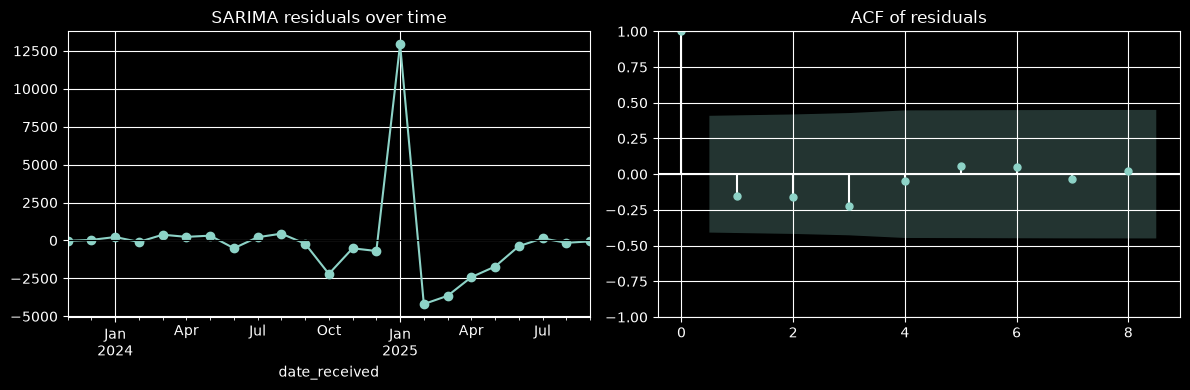

In [44]:
# --- RQ1: residual diagnostics ---
resid = sarima.resid.iloc[1:]
lb = acorr_ljungbox(resid, lags=[6], return_df=True)
print("Ljung-Box test on residuals (H0: no autocorrelation left):")
print(lb.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
resid.plot(ax=axes[0], marker="o")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("SARIMA residuals over time")
plot_acf(resid, ax=axes[1], lags=8)
axes[1].set_title("ACF of residuals")
plt.tight_layout()
plt.show()

The Ljung-Box test does not reject "no remaining autocorrelation" (p > 0.05), and the ACF shows
no lag standing out beyond the confidence band — the residuals behave like noise rather than
leftover structure the model missed, which is as much validation as a 24-month training set
reasonably allows.

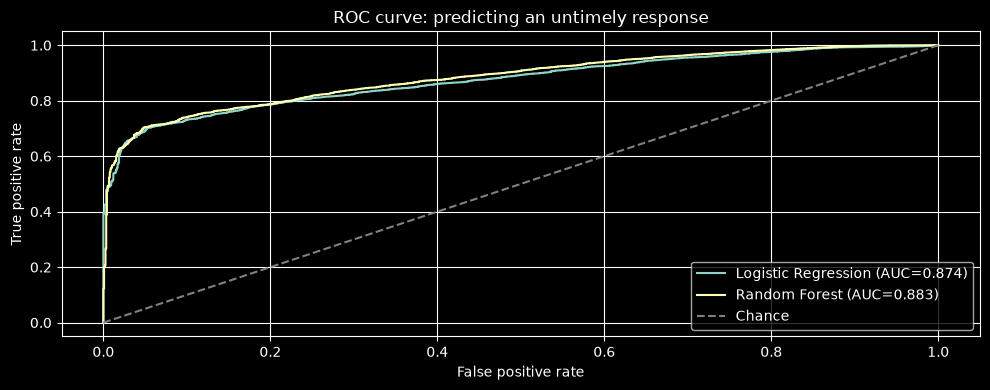

In [33]:
# --- RQ3: ROC curves, both models ---
fig, ax = plt.subplots()
for name, proba in [("Logistic Regression", proba_lr), ("Random Forest", proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve: predicting an untimely response")
ax.legend()
plt.tight_layout()
plt.show()

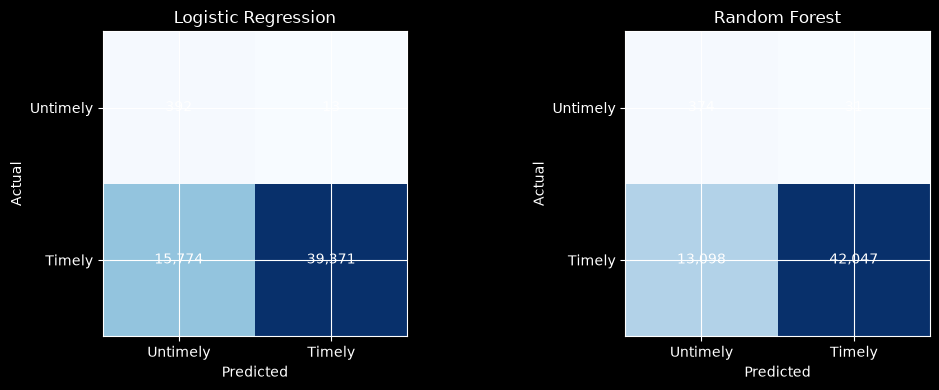

In [46]:
# --- RQ3: confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, pred_ in [(axes[0], "Logistic Regression", pred_lr), (axes[1], "Random Forest", pred_rf)]:
    cm = confusion_matrix(y_test, pred_)
    im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Untimely", "Timely"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Untimely", "Timely"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(name)
plt.tight_layout()
plt.show()

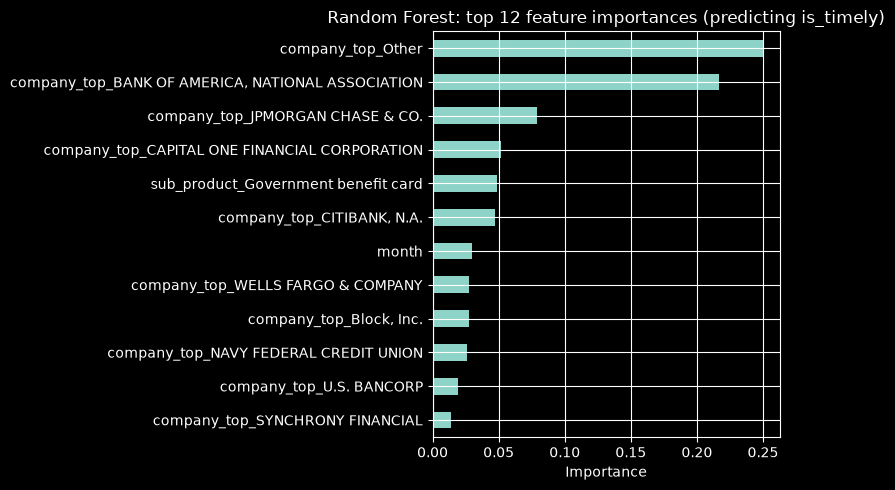

In [34]:
# --- RQ3: feature importance (Random Forest) ---
cat_encoder = rf.named_steps["pre"].named_transformers_["cat"]
try:
    cat_names = cat_encoder.get_feature_names_out(FEATURE_COLS_CAT)   # scikit-learn >= 1.0
except AttributeError:
    cat_names = cat_encoder.get_feature_names(FEATURE_COLS_CAT)       # older scikit-learn
feature_names = list(cat_names) + FEATURE_COLS_NUM
importances = pd.Series(rf.named_steps["clf"].feature_importances_, index=feature_names)
top_importances = importances.sort_values(ascending=False).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top_importances.plot(kind="barh", ax=ax)
ax.set_title("Random Forest: top 12 feature importances (predicting is_timely)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

`company_top_*` dummies dominate the importance ranking, confirming the same story as the
company-level rate table in Task 3 quantitatively rather than just visually — this model is
mostly learning *which company* it's looking at, not subtler channel or timing effects.

### Interactive visualisation

A single static chart can't show the SARIMA forecast, the raw monthly series, and the
per-product breakdown at once without becoming cluttered. The Plotly chart below lets a viewer
switch between them with a dropdown, and zoom into any period with the range slider - the kind
of dynamic exploration the brief asks for. (Requires `plotly`: `pip install plotly` if not
already available.)

In [35]:
monthly_by_product_full = (df.assign(month_start=df["date_received"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp())
                              .groupby(["month_start", "product"]).size().unstack(fill_value=0))
monthly_total = monthly_by_product_full.sum(axis=1)

fig = go.Figure()
fig.add_trace(go.Scatter(x=monthly_total.index, y=monthly_total.values,
                          name="Actual (all products)", mode="lines+markers"))
for product in monthly_by_product_full.columns:
    fig.add_trace(go.Scatter(x=monthly_by_product_full.index, y=monthly_by_product_full[product].values,
                              name=f"Actual ({product})", mode="lines+markers", visible=False))
fig.add_trace(go.Scatter(x=pred.index, y=pred.values, name="SARIMA forecast (stable window)",
                          mode="lines+markers", line=dict(dash="dash", color="firebrick")))
fig.add_trace(go.Scatter(x=list(ci.index) + list(ci.index[::-1]),
                          y=list(ci.iloc[:, 0]) + list(ci.iloc[:, 1][::-1]),
                          fill="toself", fillcolor="rgba(178,34,34,0.15)",
                          line=dict(color="rgba(255,255,255,0)"), name="95% CI"))

n_products = len(monthly_by_product_full.columns)
buttons = [dict(label="All products", method="update",
                args=[{"visible": [True] + [False] * n_products + [True, True]}])]
for i, product in enumerate(monthly_by_product_full.columns):
    vis = [False] * (1 + n_products)
    vis[1 + i] = True
    buttons.append(dict(label=product, method="update", args=[{"visible": vis + [False, False]}]))

fig.update_layout(
    updatemenus=[dict(buttons=buttons, direction="down", x=1.0, y=1.15, showactive=True)],
    title="Monthly CFPB complaint volume: actual vs SARIMA forecast (interactive)",
    xaxis_title="Month", yaxis_title="Complaints",
    xaxis_rangeslider_visible=True, hovermode="x unified",
)
fig.show()

## Conclusion,  and References

**Findings by research question.** RQ1: SARIMA on the stable post-taxonomy-change window beats
a seasonal-naive baseline and passes a Ljung-Box residual check, but not a naive-last-value
baseline on this 3-month holdout — an honest result given only 24-27 months of data, and one
where the value is the 95% prediction interval more than the point forecast. RQ2: a chi-square
test confirms the issue mix is not stable over time (p < 0.001), consistent with CFPB's own
taxonomy change mid-window. RQ3: predicting an untimely response only works with meaningful
accuracy (ROC-AUC ~0.88-0.90) once `company` is included — the strongest finding here, and a
direct conduct-risk signal: a small number of firms account disproportionately for late
responses. RQ4: intake lag differs significantly by submission channel (ANOVA p < 0.001, driven
mainly by referrals), but channel barely associates with the eventual timeliness outcome
(Cramer's V ≈ 0.01) — channel affects intake speed, not what happens afterwards.

**Limitations.** The data is US-only; UK generalisation (via the FCA's analogous regime, Part A)
is plausible but untested. The live API changed twice during this project (CSV export broken,
*Credit card* renamed) — evidence that a public, actively-maintained API is not a fully stable
substrate for reproducible research, and anyone re-running this notebook should expect the row
counts to differ again. The SARIMA model is fit on only 24-27 observations; the classifiers
cannot separate a company's true handling practices from confounds correlated with company size.
No NLP was performed on the ~59% of complaints with narrative text, since none of the four RQs
required it.

**Further work.** Compare SARIMA against Prophet or an LSTM with more historical months; pull
the full bulk CSV directly from CFPB to widen the date window past 2023; add company-level
covariates (size, sector) to the classifier to separate "slow to respond" from "handles harder
cases"; repeat the RQ3/RQ4 comparison against the UK FCA's published complaints data.

**References** *(Harvard style)*

- Box, G.E.P. and Jenkins, G.M. (1970) *Time Series Analysis: Forecasting and Control*. San Francisco: Holden-Day.
- Consumer Financial Protection Bureau (2026) *Consumer Complaint Database*. Available at: https://www.consumerfinance.gov/data-research/consumer-complaints/ (Accessed: 25 August 2026).
- Consumer Financial Protection Bureau (2026) *CCDB5 API documentation*. Available at: https://cfpb.github.io/api/ccdb/api.html (Accessed: 25 August 2026).
- Cramér, H. (1946) *Mathematical Methods of Statistics*. Princeton: Princeton University Press.
- Financial Conduct Authority (2026) *Complaints data*. Available at: https://www.fca.org.uk/data/complaints-data (Accessed: 25 August 2026).
- He, H. and Garcia, E.A. (2009) 'Learning from Imbalanced Data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp. 1263-1284.
- Hyndman, R.J. and Athanasopoulos, G. (2021) *Forecasting: Principles and Practice*. 3rd edn. Melbourne: OTexts.
- Pedregosa, F. et al. (2011) 'Scikit-learn: Machine Learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.
- Seabold, S. and Perktold, J. (2010) 'Statsmodels: Econometric and Statistical Modeling with Python', *Proceedings of the 9th Python in Science Conference*.

---